# FedVocabHAR WISDM Phase 1A-R

## Dual-confirmation admission and cautious two-anchor inheritance

Phase 1A showed that one confirmed candidate could incorrectly transfer its label to many sensor-matched reports. Under staggered arrivals, inherited-label precision fell to 0.135. This repair notebook changes the safety invariant:

> A class can enter the global vocabulary only after matching direct semantic confirmations from at least two distinct clients.

Sensor agreement ranks confirmation opportunities. It cannot provide semantic support for promotion. The experiment reports direct-only promotion separately from optional two-anchor inheritance, so unsafe propagation cannot be hidden by correct direct labels.


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
from dataclasses import dataclass, asdict
from pathlib import Path
from itertools import combinations
from collections import defaultdict
import copy, hashlib, json, math, random, warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from scipy.stats import wilcoxon

warnings.filterwarnings('ignore')

@dataclass(frozen=True)
class Config:
    project: str = '/content/drive/MyDrive/FedVocabHAR'
    seed: int = 42
    development_subjects: tuple = tuple(range(1635,1642))
    engineering_subjects: tuple = tuple(range(1643,1651))
    development_activities: tuple = ('F','G','H','I','K')
    engineering_activities: tuple = ('L','M','O','P','Q','S')
    fragments_per_client_activity: int = 2
    max_windows_per_fragment: int = 40
    pca_components: int = 24
    target_pair_precision: float = 0.90
    fallback_negative_fpr: float = 0.01
    inheritance_margin: float = 0.05
    promotion_quorum: int = 2
    registry_precision_gate: float = 0.90
    seeds: tuple = (11,23,37,51,79)
    arrival_modes: tuple = ('synchronous','staggered')
    confirmations_per_activity: tuple = (0.5,1.0,2.0,3.0)

CFG=Config()
PROJECT=Path(CFG.project)
P0=PROJECT/'artifacts'/'phase0'
P0B=PROJECT/'artifacts'/'phase0b'
OUT=PROJECT/'artifacts'/'phase1ar'
OUT.mkdir(parents=True,exist_ok=True)
CACHE=P0/'wisdm_watch_accel_w128_s64.npz'
MODEL=P0B/'contrastive_encoder.pt'
assert CACHE.exists(), f'Missing Phase Zero cache: {CACHE}'
assert MODEL.exists(), f'Missing Phase Zero-B encoder: {MODEL}'

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

seed_all(CFG.seed)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:',DEVICE)
print('project:',PROJECT)
print(json.dumps(asdict(CFG),indent=2))


device: cuda
project: /content/drive/MyDrive/FedVocabHAR
{
  "project": "/content/drive/MyDrive/FedVocabHAR",
  "seed": 42,
  "development_subjects": [
    1635,
    1636,
    1637,
    1638,
    1639,
    1640,
    1641
  ],
  "engineering_subjects": [
    1643,
    1644,
    1645,
    1646,
    1647,
    1648,
    1649,
    1650
  ],
  "development_activities": [
    "F",
    "G",
    "H",
    "I",
    "K"
  ],
  "engineering_activities": [
    "L",
    "M",
    "O",
    "P",
    "Q",
    "S"
  ],
  "fragments_per_client_activity": 2,
  "max_windows_per_fragment": 40,
  "pca_components": 24,
  "target_pair_precision": 0.9,
  "fallback_negative_fpr": 0.01,
  "inheritance_margin": 0.05,
  "promotion_quorum": 2,
  "registry_precision_gate": 0.9,
  "seeds": [
    11,
    23,
    37,
    51,
    79
  ],
  "arrival_modes": [
    "synchronous",
    "staggered"
  ],
  "confirmations_per_activity": [
    0.5,
    1.0,
    2.0,
    3.0
  ]
}


## Load the fixed Phase Zero cache and encoder

The representation is fixed before Phase 1A. Development activities may train and calibrate the compatibility model. Engineering activity names remain private to the confirmation oracle and evaluator.


In [3]:
d=np.load(CACHE)
x=d['x'].astype(np.float32)
subjects=d['subject'].astype(int)
activities=d['activity'].astype(str)
positions=d['position'].astype(np.float32)

class Encoder(nn.Module):
    def __init__(self,dim):
        super().__init__()
        self.body=nn.Sequential(
            nn.Conv1d(3,64,7,padding=3),nn.BatchNorm1d(64),nn.ReLU(),
            nn.Conv1d(64,96,5,stride=2,padding=2),nn.BatchNorm1d(96),nn.ReLU(),
            nn.Conv1d(96,128,5,stride=2,padding=2),nn.BatchNorm1d(128),nn.ReLU(),
            nn.Conv1d(128,128,3,padding=1),nn.BatchNorm1d(128),nn.ReLU(),
            nn.AdaptiveAvgPool1d(1))
        self.project=nn.Sequential(nn.Linear(128,128),nn.ReLU(),nn.Linear(128,dim))
    def forward(self,z):
        h=self.body(z).squeeze(-1)
        return F.normalize(self.project(h),dim=1)

# Phase Zero-B created this checkpoint inside the same FedVocabHAR project.
# PyTorch 2.6+ defaults to weights_only=True, which rejects the stored NumPy
# normalization arrays. Explicitly permit the trusted project checkpoint.
try:
    checkpoint=torch.load(MODEL,map_location='cpu',weights_only=False)
except TypeError:  # Compatibility with older PyTorch releases.
    checkpoint=torch.load(MODEL,map_location='cpu')
dim=int(checkpoint['config']['embedding_dim'])
encoder=Encoder(dim).to(DEVICE)
encoder.load_state_dict(checkpoint['state_dict'])
encoder.eval()
channel_mean=np.asarray(checkpoint['channel_mean'],dtype=np.float32)
channel_std=np.asarray(checkpoint['channel_std'],dtype=np.float32)
xn=(x-channel_mean)/channel_std

emb=[]
with torch.no_grad():
    for start in range(0,len(xn),512):
        emb.append(encoder(torch.from_numpy(xn[start:start+512]).to(DEVICE)).cpu().numpy())
emb=np.concatenate(emb).astype(np.float32)
print('windows:',x.shape,'embeddings:',emb.shape)
print(pd.crosstab(subjects,activities).to_string())


windows: (19704, 3, 128) embeddings: (19704, 96)
col_0    A    B    C    D    E    F    G    H    I    K    L    M    O    P    Q    R    S
row_0                                                                                     
1635    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1636    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1637   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1638   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1639   138  138  138  138  138  138  138  138  138  138    0  138  138  138  138  138  138
1640   138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138  138
1641    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1643    55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55   55
1644    55   55   55   55   55   55   55 

In [4]:
def signal_features(a,fs=20.0):
    mag=np.linalg.norm(a,axis=1,keepdims=True)
    z=np.concatenate([a,mag],axis=1)
    centered=z-z.mean(2,keepdims=True)
    std=centered.std(2)+1e-8
    feats=[]
    funcs=[lambda q:q.mean(2),lambda q:q.std(2),lambda q:np.median(q,2),
           lambda q:np.quantile(q,.10,axis=2),lambda q:np.quantile(q,.25,axis=2),
           lambda q:np.quantile(q,.75,axis=2),lambda q:np.quantile(q,.90,axis=2),
           lambda q:np.sqrt((q*q).mean(2)),lambda q:np.abs(q).mean(2),
           lambda q:np.sqrt((np.diff(q,axis=2)**2).mean(2))]
    feats += [fn(z) for fn in funcs]
    feats.append((np.diff(np.signbit(centered),axis=2)!=0).mean(2))
    feats.append((centered[:,:,:-1]*centered[:,:,1:]).mean(2)/(std*std))
    fft=np.abs(np.fft.rfft(centered,axis=2))**2
    freqs=np.fft.rfftfreq(z.shape[2],1/fs); fft[:,:,0]=0
    total=fft.sum(2)+1e-8; prob=fft/total[:,:,None]
    feats += [(fft*freqs).sum(2)/total,freqs[np.argmax(fft,axis=2)],-(prob*np.log(prob+1e-12)).sum(2)]
    for lo,hi in [(0,.5),(.5,1.5),(1.5,3),(3,5),(5,10.1)]:
        band=(freqs>=lo)&(freqs<hi); feats.append(fft[:,:,band].sum(2)/total)
    feats.append(np.stack([
        (centered[:,0]*centered[:,1]).mean(1)/(std[:,0]*std[:,1]),
        (centered[:,0]*centered[:,2]).mean(1)/(std[:,0]*std[:,2]),
        (centered[:,1]*centered[:,2]).mean(1)/(std[:,1]*std[:,2])],1))
    return np.nan_to_num(np.concatenate(feats,1).astype(np.float32))

sf=signal_features(x)
dev_window=np.isin(subjects,CFG.development_subjects) & np.isin(activities,CFG.development_activities)
sf_pipe=Pipeline([('scale',StandardScaler()),('pca',PCA(CFG.pca_components,random_state=CFG.seed))])
em_pipe=Pipeline([('scale',StandardScaler()),('pca',PCA(CFG.pca_components,random_state=CFG.seed))])
sf_red=sf_pipe.fit(sf[dev_window]).transform(sf).astype(np.float32)
em_red=em_pipe.fit(emb[dev_window]).transform(emb).astype(np.float32)
print('reduced features:',sf_red.shape,em_red.shape)


reduced features: (19704, 24) (19704, 24)


## Construct oracle pure local candidates

Candidates are contiguous fragments within a client and activity episode. The activity field is removed from the public table immediately after construction. Only the private oracle and evaluator retain it.


In [5]:
def evenly_limit(idx,limit):
    if len(idx)<=limit: return idx
    take=np.linspace(0,len(idx)-1,limit).round().astype(int)
    return idx[take]

def build_candidates(subject_set,activity_set,prefix):
    rows=[]; descriptors=[]; stat_centers=[]; emb_centers=[]; private={}
    cid=0
    for subject in subject_set:
        for activity in activity_set:
            idx=np.where((subjects==subject)&(activities==activity))[0]
            if len(idx)<CFG.fragments_per_client_activity: continue
            idx=idx[np.argsort(positions[idx])]
            for fragment,part in enumerate(np.array_split(idx,CFG.fragments_per_client_activity)):
                part=evenly_limit(part,CFG.max_windows_per_fragment)
                if len(part)==0: continue
                smean,sstd=sf_red[part].mean(0),sf_red[part].std(0)
                emean,estd=em_red[part].mean(0),em_red[part].std(0)
                descriptor=np.concatenate([smean,sstd,emean,estd]).astype(np.float32)
                candidate_id=f'{prefix}_{cid:04d}'
                rows.append({'candidate_id':candidate_id,'subject':int(subject),'fragment':int(fragment),
                             'support':int(len(part)),'time_center':float(positions[part].mean())})
                descriptors.append(descriptor); stat_centers.append(smean); emb_centers.append(emean)
                private[candidate_id]=str(activity); cid+=1
    public=pd.DataFrame(rows)
    forbidden={'activity','true_activity','label','y'} & set(public.columns)
    assert not forbidden, f'Hidden-label leakage in public table: {forbidden}'
    return public,np.stack(descriptors),np.stack(stat_centers),np.stack(emb_centers),private

dev_public,dev_desc,dev_stat,dev_emb,dev_oracle=build_candidates(
    CFG.development_subjects,CFG.development_activities,'dev')
eng_public,eng_desc,eng_stat,eng_emb,eng_oracle=build_candidates(
    CFG.engineering_subjects,CFG.engineering_activities,'eng')
print('development candidates:',len(dev_public),'engineering candidates:',len(eng_public))
display(dev_public.head())
assert set(eng_public.candidate_id)==set(eng_oracle)


development candidates: 70 engineering candidates: 96


,candidate_id,subject,fragment,support,time_center
0,dev_0000,1635,0,28,0.248490
1,dev_0001,1635,1,27,0.754674
2,dev_0002,1635,0,28,0.248490
3,dev_0003,1635,1,27,0.754674
4,dev_0004,1635,0,28,0.248419


## Fit and calibrate compatibility on development activities only

The compatibility model learns from development candidates. Calibration first searches for a threshold that reaches 0.90 development pair precision with at least five selected pairs. If none exists, it falls back to a one-percent negative-tail threshold and records the fallback explicitly.


In [6]:
def pair_feature(a,b):
    na=np.linalg.norm(a)+1e-8; nb=np.linalg.norm(b)+1e-8
    return np.concatenate([np.abs(a-b),a*b,[float(a@b/(na*nb)),float(na),float(nb)]])

def pair_rows(public,desc,oracle,allowed_subjects):
    ids=public.candidate_id.tolist(); id_to_i={v:i for i,v in enumerate(ids)}
    out=[]
    for ia,ib in combinations(range(len(ids)),2):
        ra,rb=public.iloc[ia],public.iloc[ib]
        if ra.subject==rb.subject: continue
        if int(ra.subject) not in allowed_subjects or int(rb.subject) not in allowed_subjects: continue
        out.append((pair_feature(desc[ia],desc[ib]),int(oracle[ids[ia]]==oracle[ids[ib]])))
    return np.stack([q[0] for q in out]),np.asarray([q[1] for q in out])

train_subjects=set(CFG.development_subjects[:-2]); cal_subjects=set(CFG.development_subjects[-2:])
Xtr,ytr=pair_rows(dev_public,dev_desc,dev_oracle,train_subjects)
Xcal,ycal=pair_rows(dev_public,dev_desc,dev_oracle,cal_subjects)
matcher=Pipeline([('scale',StandardScaler()),('lr',LogisticRegression(max_iter=3000,class_weight='balanced',random_state=CFG.seed))])
matcher.fit(Xtr,ytr)
cal_score=matcher.predict_proba(Xcal)[:,1]

def choose_threshold(y,score,target,min_selected=5,fallback_fpr=.01):
    candidates=[]
    for threshold in np.unique(score):
        selected=score>=threshold
        if selected.sum()<min_selected: continue
        precision=float(y[selected].mean())
        recall=float((selected & (y==1)).sum()/max(1,(y==1).sum()))
        if precision>=target: candidates.append((recall,-threshold,threshold,precision,int(selected.sum())))
    if candidates:
        _,_,threshold,precision,n=max(candidates)
        return float(threshold),{'status':'target_precision','precision':precision,'selected':n}
    negatives=score[y==0]
    threshold=float(np.quantile(negatives,1-fallback_fpr))
    selected=score>=threshold
    return threshold,{'status':'negative_tail_fallback','precision':float(y[selected].mean()) if selected.any() else None,
                      'selected':int(selected.sum()),'fallback_fpr':fallback_fpr}

PAIR_THRESHOLD,threshold_record=choose_threshold(ycal,cal_score,CFG.target_pair_precision,
                                                  fallback_fpr=CFG.fallback_negative_fpr)
calibration={'auroc':float(roc_auc_score(ycal,cal_score)),'average_precision':float(average_precision_score(ycal,cal_score)),
             'threshold':PAIR_THRESHOLD,**threshold_record}
print(json.dumps(calibration,indent=2))


{
  "auroc": 0.49124999999999996,
  "average_precision": 0.20950857461971548,
  "threshold": 0.9999999999999362,
  "status": "negative_tail_fallback",
  "precision": 0.0,
  "selected": 1,
  "fallback_fpr": 0.01
}


In [7]:
def cosine_matrix(a):
    z=a/(np.linalg.norm(a,axis=1,keepdims=True)+1e-8)
    return np.clip((z@z.T+1)/2,0,1)

def compatibility_matrix(public,desc):
    n=len(public); P=np.eye(n,dtype=np.float32)
    for i,j in combinations(range(n),2):
        q=float(matcher.predict_proba(pair_feature(desc[i],desc[j])[None])[0,1])
        P[i,j]=P[j,i]=q
    return P

P=compatibility_matrix(eng_public,eng_desc)
P_stat=cosine_matrix(eng_stat); P_emb=cosine_matrix(eng_emb)
np.fill_diagonal(P,0); np.fill_diagonal(P_stat,0); np.fill_diagonal(P_emb,0)

ids=eng_public.candidate_id.tolist(); hidden=np.array([eng_oracle[q] for q in ids])
pair_y=[]; pair_s=[]
for i,j in combinations(range(len(ids)),2):
    if eng_public.iloc[i].subject==eng_public.iloc[j].subject: continue
    pair_y.append(int(hidden[i]==hidden[j])); pair_s.append(float(P[i,j]))
engineering_pair_diagnostic={'auroc':float(roc_auc_score(pair_y,pair_s)),
                             'average_precision':float(average_precision_score(pair_y,pair_s)),
                             'tpr':float(np.mean(np.asarray(pair_s)[np.asarray(pair_y)==1]>=PAIR_THRESHOLD)),
                             'fpr':float(np.mean(np.asarray(pair_s)[np.asarray(pair_y)==0]>=PAIR_THRESHOLD))}
print(json.dumps(engineering_pair_diagnostic,indent=2))


{
  "auroc": 0.665760080073696,
  "average_precision": 0.2356294288693847,
  "tpr": 0.6309523809523809,
  "fpr": 0.3952380952380952
}


## Calibrate an ensemble agreement score for optional inheritance

The original logistic compatibility score was saturated under activity shift. Phase 1A-R therefore uses the minimum agreement across the learned matcher, signal statistics, and self-supervised representation. The inheritance threshold is calibrated only on development candidates. Failure to obtain a valid threshold disables inheritance; it does not weaken direct-confirmation promotion.


In [8]:
def pair_score_matrix(public,desc,stat,embedding):
    learned=compatibility_matrix(public,desc)
    stat_sim=cosine_matrix(stat); emb_sim=cosine_matrix(embedding)
    np.fill_diagonal(learned,0); np.fill_diagonal(stat_sim,0); np.fill_diagonal(emb_sim,0)
    rank_score=(learned+stat_sim+emb_sim)/3
    safe_score=np.minimum(np.minimum(learned,stat_sim),emb_sim)
    return learned,stat_sim,emb_sim,rank_score,safe_score

dev_learned,dev_stat_sim,dev_emb_sim,dev_rank,dev_safe=pair_score_matrix(
    dev_public,dev_desc,dev_stat,dev_emb)
eng_learned,eng_stat_sim,eng_emb_sim,RANK_SCORE,SAFE_SCORE=pair_score_matrix(
    eng_public,eng_desc,eng_stat,eng_emb)

def cross_client_pair_vectors(public,oracle,matrix,subject_filter=None):
    y=[]; score=[]
    for i,j in combinations(range(len(public)),2):
        if public.iloc[i].subject==public.iloc[j].subject: continue
        if subject_filter is not None and (int(public.iloc[i].subject) not in subject_filter or
                                           int(public.iloc[j].subject) not in subject_filter): continue
        y.append(int(oracle[public.iloc[i].candidate_id]==oracle[public.iloc[j].candidate_id]))
        score.append(float(matrix[i,j]))
    return np.asarray(y),np.asarray(score)

ys,ss=cross_client_pair_vectors(dev_public,dev_oracle,dev_safe,set(CFG.development_subjects[-2:]))
SAFE_THRESHOLD,safe_threshold_record=choose_threshold(
    ys,ss,CFG.target_pair_precision,min_selected=5,fallback_fpr=CFG.fallback_negative_fpr)
safe_calibration={'auroc':float(roc_auc_score(ys,ss)),'average_precision':float(average_precision_score(ys,ss)),
                  'threshold':SAFE_THRESHOLD,**safe_threshold_record}

ye,se=cross_client_pair_vectors(eng_public,eng_oracle,SAFE_SCORE)
safe_engineering={'auroc':float(roc_auc_score(ye,se)),'average_precision':float(average_precision_score(ye,se)),
                  'tpr':float(np.mean(se[ye==1]>=SAFE_THRESHOLD)),
                  'fpr':float(np.mean(se[ye==0]>=SAFE_THRESHOLD))}
INHERITANCE_AVAILABLE=(safe_calibration['status']=='target_precision' and
                       safe_calibration.get('precision',0)>=CFG.target_pair_precision)
print('safe calibration:',json.dumps(safe_calibration,indent=2))
print('engineering diagnostic:',json.dumps(safe_engineering,indent=2))
print('inheritance available from development evidence:',INHERITANCE_AVAILABLE)


safe calibration: {
  "auroc": 0.415625,
  "average_precision": 0.16774065988463885,
  "threshold": 0.5547748398780823,
  "status": "negative_tail_fallback",
  "precision": 0.0,
  "selected": 1,
  "fallback_fpr": 0.01
}
engineering diagnostic: {
  "auroc": 0.72937570861678,
  "average_precision": 0.3906543728211629,
  "tpr": 0.7098214285714286,
  "fpr": 0.430952380952381
}
inheritance available from development evidence: False


## Query policies

- **Random:** uniform selection among arrived, unqueried candidates.
- **Entropy:** selects the candidate with highest average pair uncertainty.
- **Dual similarity:** tries to find a second client for a label with only one direct confirmation; otherwise selects a high-density candidate.
- **FedVocabHAR-R:** balances second-confirmation value, exploration of uncovered regions, candidate density, agreement across evidence channels, and redundancy with already promoted labels.

All policies receive the same public arrival schedule and evidence. Only the confirmation oracle and evaluator can access engineering activity identities.


In [9]:
POLICIES=('random','entropy','dual_similarity','fedvocabhar_r')
PUBLIC_COLUMNS=('candidate_id','subject','fragment','support','time_center','arrival_round')

def norm(v):
    v=np.asarray(v,dtype=float); lo,hi=np.nanmin(v),np.nanmax(v)
    return np.zeros_like(v) if hi-lo<1e-12 else (v-lo)/(hi-lo)

def binary_entropy(q):
    q=np.clip(q,1e-6,1-1e-6)
    return -(q*np.log(q)+(1-q)*np.log(1-q))

def label_subjects(direct):
    out=defaultdict(set)
    for i,label in direct.items(): out[label].add(int(eng_public.iloc[i].subject))
    return out

def promoted_labels(direct):
    return {label for label,subs in label_subjects(direct).items() if len(subs)>=CFG.promotion_quorum}

def policy_table(eligible,direct):
    eligible=np.asarray(eligible,dtype=int); queried=set(direct)
    by_label=defaultdict(list)
    for i,label in direct.items(): by_label[label].append(i)
    promoted=promoted_labels(direct)
    singleton=[i for label,seeds in by_label.items() if label not in promoted for i in seeds]
    promoted_seed=[i for label,seeds in by_label.items() if label in promoted for i in seeds]
    rows=[]
    for i in eligible:
        peers=[j for j in eligible if j!=i and eng_public.iloc[j].subject!=eng_public.iloc[i].subject]
        q=RANK_SCORE[i,peers] if peers else np.asarray([0.0])
        valid_single=[j for j in singleton if eng_public.iloc[j].subject!=eng_public.iloc[i].subject]
        verify=max([RANK_SCORE[i,j] for j in valid_single],default=0.0)
        explore=1-max([RANK_SCORE[i,j] for j in queried],default=0.0)
        density=float(np.mean(np.sort(q)[-min(5,len(q)):])) if len(q) else 0.0
        agreement=1-float(np.mean(np.abs(eng_stat_sim[i,peers]-eng_emb_sim[i,peers]))) if peers else 0.0
        promoted_red=max([RANK_SCORE[i,j] for j in promoted_seed],default=0.0)
        entropy=float(binary_entropy(q).mean())
        rows.append({'candidate_index':i,'entropy':entropy,'verify_gain':verify,'explore_gain':explore,
                     'density':density,'channel_agreement':agreement,'promoted_redundancy':promoted_red})
    tab=pd.DataFrame(rows)
    for col in ['entropy','verify_gain','explore_gain','density','channel_agreement','promoted_redundancy']:
        tab[col]=norm(tab[col])
    tab['fedvocabhar_r_score']=(.38*tab.verify_gain+.30*tab.explore_gain+.15*tab.density+
                                .17*tab.channel_agreement-.55*tab.promoted_redundancy)
    return tab

def select_candidate(policy,eligible,direct,rng):
    tab=policy_table(eligible,direct)
    if policy=='random': chosen=int(rng.choice(eligible))
    elif policy=='entropy': chosen=int(tab.sort_values(['entropy','explore_gain'],ascending=False).iloc[0].candidate_index)
    elif policy=='dual_similarity':
        if tab.verify_gain.max()>0:
            chosen=int(tab.sort_values(['verify_gain','promoted_redundancy'],ascending=[False,True]).iloc[0].candidate_index)
        else: chosen=int(tab.sort_values(['density','explore_gain'],ascending=False).iloc[0].candidate_index)
    elif policy=='fedvocabhar_r':
        jitter=rng.normal(0,1e-9,len(tab))
        chosen=int(tab.iloc[np.argmax(tab.fedvocabhar_r_score.to_numpy()+jitter)].candidate_index)
    else: raise ValueError(policy)
    return chosen,tab

def confirmation_oracle(candidate_index,log,step):
    cid=eng_public.iloc[candidate_index].candidate_id
    label=eng_oracle[cid]
    log.append({'step':step,'candidate_id':cid,'returned_label':label})
    return label


## Direct promotion and cautious two-anchor inheritance

Direct confirmations alone determine promotion. The optional inherited track activates only if development calibration achieved the target precision. A report must agree with at least two directly confirmed anchors of one promoted label and remain separated from competing labels by the configured margin.


In [10]:
def cautious_inheritance(direct):
    assignments=dict(direct); conflicts=set()
    promoted=promoted_labels(direct)
    if not INHERITANCE_AVAILABLE or not promoted: return assignments,conflicts
    by_label=defaultdict(list)
    for i,label in direct.items(): by_label[label].append(i)
    for j in range(len(eng_public)):
        if j in direct: continue
        scores=[]
        for label in promoted:
            anchors=[i for i in by_label[label] if eng_public.iloc[i].subject!=eng_public.iloc[j].subject]
            vals=sorted([SAFE_SCORE[j,i] for i in anchors],reverse=True)
            score=float(vals[1]) if len(vals)>=2 else 0.0
            scores.append((score,label))
        scores=sorted(scores,reverse=True)
        if not scores or scores[0][0]<SAFE_THRESHOLD: continue
        if len(scores)>1 and scores[0][0]-scores[1][0]<CFG.inheritance_margin:
            conflicts.add(j); continue
        assignments[j]=scores[0][1]
    return assignments,conflicts

def evaluate(direct,assignments,queries):
    promoted=promoted_labels(direct)
    subjects_by_label=label_subjects(direct)
    useful=sum(min(CFG.promotion_quorum,len(v)) for v in subjects_by_label.values())
    direct_unique=len(subjects_by_label)
    inherited=[i for i in assignments if i not in direct]
    inherited_correct=sum(assignments[i]==eng_oracle[eng_public.iloc[i].candidate_id] for i in inherited)
    all_correct=sum(label==eng_oracle[eng_public.iloc[i].candidate_id] for i,label in assignments.items())
    return {
        'promoted_activity_coverage':len(promoted)/len(CFG.engineering_activities),
        'promoted_classes':len(promoted),
        'confirmations_per_promoted_class':queries/len(promoted) if promoted else np.inf,
        'unique_activities_queried':direct_unique,
        'duplicate_or_nonquorum_confirmations':queries-useful,
        'single_confirmation_promotions':sum(len(v)<CFG.promotion_quorum for k,v in subjects_by_label.items() if k in promoted),
        'direct_registry_precision':1.0 if direct else np.nan,
        'direct_report_coverage':len(direct)/len(eng_public),
        'inherited_count':len(inherited),
        'inherited_precision':inherited_correct/len(inherited) if inherited else np.nan,
        'inherited_report_coverage':len(inherited)/len(eng_public),
        'combined_registry_precision':all_correct/len(assignments) if assignments else np.nan,
        'combined_report_coverage':len(assignments)/len(eng_public)
    }

def run_policy(policy,budget,scenario_seed,arrival_mode):
    rng=np.random.default_rng(scenario_seed)
    public=eng_public.copy()[list(PUBLIC_COLUMNS[:-1])]
    public['arrival_round']=0 if arrival_mode=='synchronous' else rng.integers(0,max(1,budget),len(public))
    assert tuple(public.columns)==PUBLIC_COLUMNS
    direct={}; prior_promoted=set(); events=[]; scores=[]; oracle=[]; clock=0
    while len(direct)<budget:
        eligible=[i for i in range(len(public)) if i not in direct and int(public.iloc[i].arrival_round)<=clock]
        if not eligible:
            future=public.loc[[i not in direct for i in range(len(public))],'arrival_round']
            if len(future)==0: break
            clock=max(clock+1,int(future.min())); continue
        chosen,tab=select_candidate(policy,eligible,direct,rng)
        tab=tab.copy(); tab['candidate_id']=tab.candidate_index.map(lambda i:public.iloc[int(i)].candidate_id)
        tab['policy']=policy; tab['step']=len(direct)+1; tab['chosen']=tab.candidate_index.eq(chosen)
        tab['budget']=budget; tab['scenario_seed']=scenario_seed; tab['arrival_mode']=arrival_mode
        scores.append(tab)
        label=confirmation_oracle(chosen,oracle,len(direct)+1); direct[chosen]=label
        now_promoted=promoted_labels(direct)
        base={'step':len(direct),'clock':clock,'policy':policy,'budget':budget,
              'scenario_seed':scenario_seed,'arrival_mode':arrival_mode}
        events.append({**base,'action':'direct_confirmation','candidate_id':public.iloc[chosen].candidate_id,
                       'subject':int(public.iloc[chosen].subject),'registry_label':label})
        for old_i,old_label in direct.items():
            if old_i!=chosen and old_label!=label:
                events.append({**base,'action':'cannot_link','candidate_id':public.iloc[chosen].candidate_id,
                               'subject':int(public.iloc[chosen].subject),'registry_label':f'{label}!={old_label}'})
        for promoted in sorted(now_promoted-prior_promoted):
            events.append({**base,'action':'dual_confirmed_promotion','candidate_id':None,
                           'subject':None,'registry_label':promoted})
        prior_promoted=now_promoted; clock+=1
    assignments,conflicts=cautious_inheritance(direct)
    metrics=evaluate(direct,assignments,len(direct))
    metrics.update({'policy':policy,'budget':budget,'scenario_seed':scenario_seed,'arrival_mode':arrival_mode,
                    'queries_used':len(direct),'conflicts':len(conflicts),'safe_threshold':SAFE_THRESHOLD,
                    'inheritance_available':INHERITANCE_AVAILABLE})
    assigned=[]
    for i,label in assignments.items():
        assigned.append({'policy':policy,'budget':budget,'scenario_seed':scenario_seed,'arrival_mode':arrival_mode,
                         'candidate_id':public.iloc[i].candidate_id,'subject':int(public.iloc[i].subject),
                         'assigned_label':label,'true_label':eng_oracle[public.iloc[i].candidate_id],
                         'source':'direct' if i in direct else 'inherited'})
    return metrics,events,scores,assigned,oracle


## Run paired experiments

The primary budget is two confirmations per true activity, matching the minimum evidence needed to promote every class. Lower budgets test scarcity; three confirmations per activity tests whether policies waste additional queries after classes are promoted.


In [11]:
summary=[]; events=[]; scores=[]; assignments=[]; oracle_audit=[]
n_activities=len(CFG.engineering_activities)
for per_activity in CFG.confirmations_per_activity:
    budget=max(1,int(math.ceil(per_activity*n_activities)))
    for arrival_mode in CFG.arrival_modes:
        for scenario_seed in CFG.seeds:
            for policy in POLICIES:
                m,e,s,a,o=run_policy(policy,budget,scenario_seed,arrival_mode)
                m['confirmations_per_activity_budget']=per_activity
                summary.append(m); events.extend(e); scores.extend(s); assignments.extend(a)
                oracle_audit.extend([{**q,'policy':policy,'budget':budget,'scenario_seed':scenario_seed,
                                      'arrival_mode':arrival_mode} for q in o])

summary=pd.DataFrame(summary); events=pd.DataFrame(events)
policy_scores=pd.concat(scores,ignore_index=True) if scores else pd.DataFrame()
assignment_log=pd.DataFrame(assignments); oracle_audit=pd.DataFrame(oracle_audit)
summary.to_csv(OUT/'phase1ar_summary.csv',index=False)
events.to_csv(OUT/'phase1ar_registry_events.csv',index=False)
policy_scores.to_csv(OUT/'phase1ar_policy_scores.csv',index=False)
assignment_log.to_csv(OUT/'phase1ar_assignments.csv',index=False)
oracle_audit.to_csv(OUT/'phase1ar_oracle_audit.csv',index=False)
display(summary.groupby(['confirmations_per_activity_budget','arrival_mode','policy'])[
    ['promoted_activity_coverage','promoted_classes','confirmations_per_promoted_class',
     'unique_activities_queried','duplicate_or_nonquorum_confirmations','inherited_precision',
     'inherited_report_coverage']].mean().round(3))


promoted_activity_coverage  \
confirmations_per_activity_budget arrival_mode policy                                        
0.5                               staggered    dual_similarity                       0.167   
                                               entropy                               0.167   
                                               fedvocabhar_r                         0.100   
                                               random                                0.133   
                                  synchronous  dual_similarity                       0.167   
                                               entropy                               0.167   
                                               fedvocabhar_r                         0.167   
                                               random                                0.000   
1.0                               staggered    dual_similarity                       0.333   
                                               entropy                               0.233   
                                               fedvocabhar_r                         0.433   
                                               random                                0.267   
                                  synchronous  dual_similarity                       0.333   
                                               entropy                               0.167   
                                               fedvocabhar_r                         0.500   
                                               random                                0.233   
2.0                               staggered    dual_similarity                       0.433   
                                               entropy                               0.333   
                                               fedvocabhar_r                         0.500   
                                               random                                0.700   
                                  synchronous  dual_similarity                       0.500   
                                               entropy                               0.333   
                                               fedvocabhar_r                         0.500   
                                               random                                0.567   
3.0                               staggered    dual_similarity                       0.500   
                                               entropy                               0.333   
                                               fedvocabhar_r                         0.533   
                                               random                                0.800   
                                  synchronous  dual_similarity                       0.500   
                                               entropy                               0.333   
                                               fedvocabhar_r                         0.500   
                                               random                                0.833   

                                                                promoted_classes  \
confirmations_per_activity_budget arrival_mode policy                              
0.5                               staggered    dual_similarity               1.0   
                                               entropy                       1.0   
                                               fedvocabhar_r                 0.6   
                                               random                        0.8   
                                  synchronous  dual_similarity               1.0   
                                               entropy                       1.0   
                                               fedvocabhar_r                 1.0   
                                               random                        0.0   
1.0                        

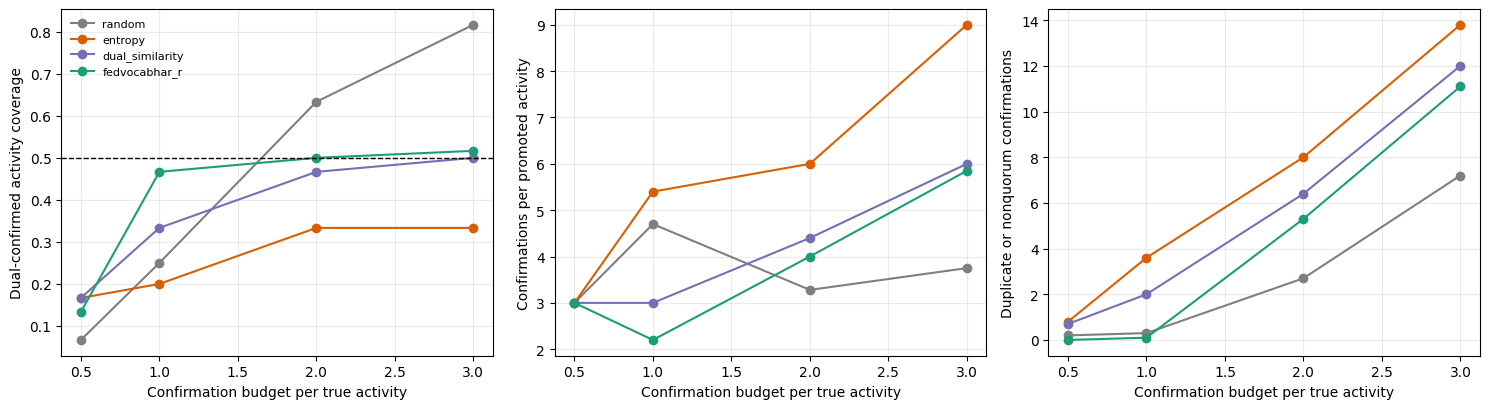

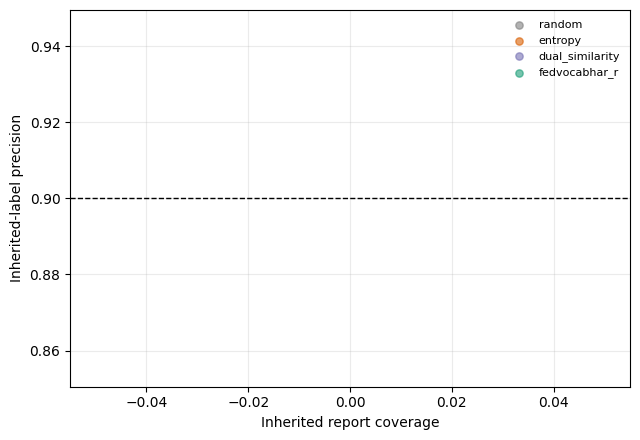

In [12]:
colors={'random':'#7f7f7f','entropy':'#d95f02','dual_similarity':'#7570b3','fedvocabhar_r':'#1b9e77'}
agg=summary.groupby(['confirmations_per_activity_budget','policy'],as_index=False).agg(
    promoted_coverage=('promoted_activity_coverage','mean'),
    confirmations_per_class=('confirmations_per_promoted_class',lambda z:np.nanmean(np.where(np.isfinite(z),z,np.nan))),
    unique_activities=('unique_activities_queried','mean'),duplicates=('duplicate_or_nonquorum_confirmations','mean'),
    inherited_precision=('inherited_precision','mean'),inherited_coverage=('inherited_report_coverage','mean'))
fig,axes=plt.subplots(1,3,figsize=(15,4.2))
for policy in POLICIES:
    q=agg[agg.policy==policy]
    axes[0].plot(q.confirmations_per_activity_budget,q.promoted_coverage,'o-',label=policy,color=colors[policy])
    axes[1].plot(q.confirmations_per_activity_budget,q.confirmations_per_class,'o-',label=policy,color=colors[policy])
    axes[2].plot(q.confirmations_per_activity_budget,q.duplicates,'o-',label=policy,color=colors[policy])
axes[0].axhline(.5,color='black',ls='--',lw=1)
axes[0].set_ylabel('Dual-confirmed activity coverage')
axes[1].set_ylabel('Confirmations per promoted activity')
axes[2].set_ylabel('Duplicate or nonquorum confirmations')
for ax in axes: ax.set_xlabel('Confirmation budget per true activity'); ax.grid(alpha=.25)
axes[0].legend(frameon=False,fontsize=8); fig.tight_layout()
fig.savefig(OUT/'phase1ar_policy_comparison.png',dpi=180,bbox_inches='tight'); plt.show()

fig,ax=plt.subplots(figsize=(6.5,4.5))
for policy in POLICIES:
    q=summary[summary.policy==policy]
    ax.scatter(q.inherited_report_coverage,q.inherited_precision,s=28,alpha=.6,label=policy,color=colors[policy])
ax.axhline(CFG.registry_precision_gate,color='black',ls='--',lw=1)
ax.set_xlabel('Inherited report coverage'); ax.set_ylabel('Inherited-label precision'); ax.grid(alpha=.25)
ax.legend(frameon=False,fontsize=8); fig.tight_layout()
fig.savefig(OUT/'phase1ar_inheritance_risk_coverage.png',dpi=180,bbox_inches='tight'); plt.show()


## Decision gates

Promotion safety is guaranteed structurally by two direct client confirmations. The empirical decision tests whether FedVocabHAR-R spends those confirmations more efficiently than random querying and whether the gain remains stable across arrival modes. Optional inheritance is enabled for later work only if its precision independently reaches 0.90.


In [13]:
primary=summary[np.isclose(summary.confirmations_per_activity_budget,2.0)].copy()

def finite_penalty(values):
    values=np.asarray(values,dtype=float); finite=values[np.isfinite(values)]
    penalty=(finite.max()*2 if len(finite) else 1e6)
    return np.where(np.isfinite(values),values,penalty)

def paired_test(left,right,metric,alternative='less'):
    key=['scenario_seed','arrival_mode','budget']
    q=left[key+[metric]].rename(columns={metric:'left'}).merge(
      right[key+[metric]].rename(columns={metric:'right'}),on=key)
    x,y=finite_penalty(q.left),finite_penalty(q.right)
    if len(q)<2 or np.allclose(x,y): return {'n':len(q),'pvalue':1.0,'median_difference':float(np.median(x-y))}
    t=wilcoxon(x,y,alternative=alternative,zero_method='zsplit')
    return {'n':len(q),'pvalue':float(t.pvalue),'median_difference':float(np.median(x-y))}

fed=primary[primary.policy=='fedvocabhar_r']; random_base=primary[primary.policy=='random']
dual_base=primary[primary.policy=='dual_similarity']
test_random=paired_test(fed,random_base,'confirmations_per_promoted_class','less')
test_dual=paired_test(fed,dual_base,'confirmations_per_promoted_class','less')
arrival_stats=fed.groupby('arrival_mode').agg(coverage=('promoted_activity_coverage','mean'),
  ce=('confirmations_per_promoted_class',lambda z:np.nanmean(np.where(np.isfinite(z),z,np.nan)))).to_dict('index')

inheritance_rows=fed[fed.inherited_count>0]
inheritance_precision=float(inheritance_rows.inherited_precision.mean()) if len(inheritance_rows) else None
gates={
 'G1_dual_confirmation_only':bool((fed.single_confirmation_promotions==0).all()),
 'G2_efficiency_vs_random':bool(test_random['median_difference']<0 and test_random['pvalue']<.05),
 'G2_efficiency_vs_dual_similarity':bool(test_dual['median_difference']<0 and test_dual['pvalue']<.05),
 'G3_coverage_each_arrival':bool(all(v['coverage']>=.50 for v in arrival_stats.values())),
 'G4_gain_direction_each_arrival':bool(all(
    fed[fed.arrival_mode==mode].confirmations_per_promoted_class.replace(np.inf,1e6).mean() <
    random_base[random_base.arrival_mode==mode].confirmations_per_promoted_class.replace(np.inf,1e6).mean()
    for mode in CFG.arrival_modes)),
 'G5_auditability':bool(len(events)>0 and len(policy_scores)>0 and len(oracle_audit)>0)
}
inheritance_gate=bool(INHERITANCE_AVAILABLE and inheritance_precision is not None and
                      inheritance_precision>=CFG.registry_precision_gate)
decision={
 'phase':'Phase 1A-R','safe_calibration':safe_calibration,'safe_engineering':safe_engineering,
 'primary_budget_confirmations_per_activity':2.0,'arrival_results':arrival_stats,
 'paired_vs_random':test_random,'paired_vs_dual_similarity':test_dual,
 'gates':gates,'proceed_to_phase1b_direct_confirmed':bool(all(gates.values())),
 'inheritance_gate':inheritance_gate,
 'inheritance_recommendation':('Eligible for Phase 1B sensitivity track.' if inheritance_gate else
    'Keep inheritance disabled; use directly confirmed candidates only.'),
 'config':asdict(CFG),
 'label_access_rule':'Engineering identities were available only to confirmation_oracle and evaluation.'
}
(OUT/'phase1ar_decision.json').write_text(json.dumps(decision,indent=2))
print(json.dumps(decision,indent=2))


{
  "phase": "Phase 1A-R",
  "safe_calibration": {
    "auroc": 0.415625,
    "average_precision": 0.16774065988463885,
    "threshold": 0.5547748398780823,
    "status": "negative_tail_fallback",
    "precision": 0.0,
    "selected": 1,
    "fallback_fpr": 0.01
  },
  "safe_engineering": {
    "auroc": 0.72937570861678,
    "average_precision": 0.3906543728211629,
    "tpr": 0.7098214285714286,
    "fpr": 0.430952380952381
  },
  "primary_budget_confirmations_per_activity": 2.0,
  "arrival_results": {
    "staggered": {
      "coverage": 0.5,
      "ce": 4.0
    },
    "synchronous": {
      "coverage": 0.5,
      "ce": 4.0
    }
  },
  "paired_vs_random": {
    "n": 10,
    "pvalue": 1.0,
    "median_difference": 1.0
  },
  "paired_vs_dual_similarity": {
    "n": 10,
    "pvalue": 0.25,
    "median_difference": 0.0
  },
  "gates": {
    "G1_dual_confirmation_only": true,
    "G2_efficiency_vs_random": false,
    "G2_efficiency_vs_dual_similarity": false,
    "G3_coverage_each_arrival

In [14]:
report=f"""# FedVocabHAR Phase 1A-R Decision Report

## Decision

**Proceed to Phase 1B with directly confirmed identities:** {decision['proceed_to_phase1b_direct_confirmed']}

**Enable optional inheritance:** {decision['inheritance_gate']}

## Paired tests at two confirmations per activity

- Versus random: p={test_random['pvalue']:.4f}, median difference={test_random['median_difference']:.3f}
- Versus dual-similarity: p={test_dual['pvalue']:.4f}, median difference={test_dual['median_difference']:.3f}

## Arrival-specific results

{json.dumps(arrival_stats,indent=2)}

## Gates

"""
for name,value in gates.items(): report+=f'- {name}: **{value}**\n'
report+=f"""

## Inheritance decision

{decision['inheritance_recommendation']}

Promotion in this experiment is based only on matching direct confirmations from distinct clients. Inherited assignments never satisfy the promotion quorum.
"""
(OUT/'FedVocabHAR_Phase1A_R_Decision_Report.md').write_text(report)
print(report); print('saved outputs to',OUT)


# FedVocabHAR Phase 1A-R Decision Report

## Decision

**Proceed to Phase 1B with directly confirmed identities:** False

**Enable optional inheritance:** False

## Paired tests at two confirmations per activity

- Versus random: p=1.0000, median difference=1.000
- Versus dual-similarity: p=0.2500, median difference=0.000

## Arrival-specific results

{
  "staggered": {
    "coverage": 0.5,
    "ce": 4.0
  },
  "synchronous": {
    "coverage": 0.5,
    "ce": 4.0
  }
}

## Gates

- G1_dual_confirmation_only: **True**
- G2_efficiency_vs_random: **False**
- G2_efficiency_vs_dual_similarity: **False**
- G3_coverage_each_arrival: **True**
- G4_gain_direction_each_arrival: **False**
- G5_auditability: **True**


## Inheritance decision

Keep inheritance disabled; use directly confirmed candidates only.

Promotion in this experiment is based only on matching direct confirmations from distinct clients. Inherited assignments never satisfy the promotion quorum.

saved outputs to /content/drive/M

## Interpretation

- If all direct-confirmation gates pass, freeze the admission policy and proceed to Phase 1B using only dual-confirmed identities.
- If efficiency fails but safety and coverage pass, retain dual-confirmation admission but revise the query utility before claiming reduced semantic burden.
- If arrival stability fails, add explicit reservation of query budget across time and retest.
- If inheritance fails, keep it disabled. Directly confirmed vocabulary integration remains scientifically valid and auditable.
